### (2) 데이터 소개

#### 1) 기본 데이터

* 학습 데이터
    * air_2021.csv : 2021년 미세먼지 데이터
    * weather_2021.csv : 2021년 날씨 데이터
* 테스트 데이터
    * air_2022.csv : 2022년 미세먼지 데이터
    * weather_2022.csv : 2022년 날씨 데이터

#### 2) 데이터셋의 변수 소개(weather_2021)

* 증기압: 증기가 고체 또는 액체와 동적 평형 상태에 있을 때 증기의 압력 (증기가 되려는 힘)
* 이슬점 온도: 불포화 상태의 공기가 냉각될 때, 포화 상태에 도달하여 수증기의 응결이 시작되는 온도
* 일조: 일정한 물체나 땅의 겉면에 태양 광선이 비치는 시간 (1시간 중 비율)
* 일사(량): 태양으로부터 오는 태양 복사 에너지가 지표에 닿는 양 (면적당 에너지 량)
* 전운량: 하늘을 육안으로 관측하여 전부 구름일 때 10, 구름이 덮고 있는 하늘의 비율에 따라 0~10
* 중하층운량: 중층과 하층에 있는 구름의 분포량(중하층 구름이 날씨에 영향 주므로 따로 표기)
* 운형(운형약어): 구름의 종류. 약어 코드로 기재됨
* 최저운고: 가장 낮은 구름의 높이
* 현상번호(국내식): 비, 소낙비, 싸락눈, 눈보라 등의 기상현상을 나타낸 코드번호
* 지면온도: 지면 0cm 온도
* 지중온도: 땅 속 온도변수1


In [21]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [22]:
# 한글 깨짐 방지 위해 구글 코랩에 나눔폰트 설치.
import sys
if 'google.colab' in sys.modules:
    !echo 'debconf debconf/frontend select Noninteractive' | debconf-set-selections
    !sudo apt-get -qq -y install fonts-nanum
    import matplotlib.font_manager as fm
    font_files = fm.findSystemFonts(fontpaths=['/usr/share/fonts/truetype/nanum'])
    for fpath in font_files:
        fm.fontManager.addfont(fpath)

# 필요한 라이브러리

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet
from sklearn.tree import DecisionTreeRegressor as DTR
from sklearn.ensemble import RandomForestRegressor as RFR
from sklearn.ensemble import GradientBoostingRegressor as GBR
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import mean_squared_error as mse
from sklearn.metrics import r2_score
from sklearn.metrics import f1_score
from sklearn.metrics import accuracy_score as acc
from sklearn.metrics import recall_score as recall

import joblib

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

In [24]:
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

## 필요한 함수

In [25]:
def vif(dataframe, features):
    """
    다중공선성(VIF)을 계산하는 함수 (const 자동 제거)

    Parameters:
    - dataframe: pd.DataFrame
        입력 데이터프레임
    - features: list of str
        독립 변수(컬럼명) 리스트

    Returns:
    - vif_df: pd.DataFrame
        독립 변수들과 해당하는 VIF 값을 담은 데이터프레임
        (const는 포함되지 않음)
    """
    X = dataframe[features]
    X_const = add_constant(X)

    vif_data = pd.DataFrame()
    vif_data["변수"] = X_const.columns
    vif_data["VIF"] = [variance_inflation_factor(X_const.values, i) for i in range(X_const.shape[1])]

    # const 행 제거
    vif_data = vif_data[vif_data["변수"] != "const"]

    return vif_data


In [26]:

def calculate_vif(X):
    """VIF 계산 (다중공선성 확인용)"""
    vif = pd.DataFrame()
    vif["변수"] = X.columns
    vif["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
    return vif

def stepwise_selection(X, y,
                       initial_list=[],
                       threshold_in=0.05,
                       threshold_out=0.05,
                       vif_threshold=10.0,
                       verbose=True):
    included = list(initial_list)
    while True:
        changed = False

        # forward step
        excluded = list(set(X.columns) - set(included))
        new_pval = pd.Series(index=excluded, dtype=float)
        for new_col in excluded:
            model = sm.OLS(y, sm.add_constant(X[included + [new_col]])).fit()
            new_pval[new_col] = model.pvalues[new_col]
        if not new_pval.empty:
            best_pval = new_pval.min()
            if best_pval < threshold_in:
                best_feature = new_pval.idxmin()
                included.append(best_feature)
                changed = True
                if verbose:
                    print(f'추가: {best_feature} (p={best_pval:.4f})')

        # backward step
        model = sm.OLS(y, sm.add_constant(X[included])).fit()
        pvalues = model.pvalues.iloc[1:]  # const 제외
        worst_pval = pvalues.max()
        if worst_pval > threshold_out:
            worst_feature = pvalues.idxmax()
            included.remove(worst_feature)
            changed = True
            if verbose:
                print(f'제거: {worst_feature} (p={worst_pval:.4f})')

        if not changed:
            break

    # 최종 모델
    final_model = sm.OLS(y, sm.add_constant(X[included])).fit()

    # VIF 확인
    vif_result = calculate_vif(X[included])
    high_vif = vif_result[vif_result["VIF"] > vif_threshold]
    if not high_vif.empty and verbose:
        print("\n다중공선성 주의 (VIF > threshold):")
        print(high_vif)

    return {
        "선택된 변수": included,
        "최종 모델": final_model,
        "VIF": vif_result
    }


# [1] 데이터 셋 불러오기

In [77]:
df_21 = pd.read_csv('/content/drive/MyDrive/AI+X/AI+X선도인재양성프로젝트(중급)/(제공용) 미세먼지 교안, 데이터 및 실습 과제/9주차/df_21.csv')
df_22 = pd.read_csv('/content/drive/MyDrive/AI+X/AI+X선도인재양성프로젝트(중급)/(제공용) 미세먼지 교안, 데이터 및 실습 과제/9주차/df_22.csv')

In [78]:
df_21 = df_21.drop(['month','day','hour', 'PM10_lag1'], axis=1)
df_22 = df_22.drop(['month','day','hour', 'PM10_lag1'], axis=1)

In [79]:
df_21.head(3)

,time,지역,SO2,CO,O3,NO2,PM10,PM25,기온(°C),강수량(mm),...,전운량(10분위),중하층운량(10분위),최저운고(100m ),시정(10m),지면온도(°C),5cm 지중온도(°C),10cm 지중온도(°C),20cm 지중온도(°C),30cm 지중온도(°C),PM10_1
0,2021-01-01 01:00:00,서울 종로구,0.002,0.5,0.022,0.016,24.0,14.0,-8.7,0.0,...,0.0,0,0.0,2000,-6.9,-1.0,-0.8,0.3,1.6,25.0
1,2021-01-01 02:00:00,서울 종로구,0.002,0.6,0.018,0.020,25.0,14.0,-9.1,0.0,...,0.0,0,0.0,2000,-7.1,-1.1,-0.8,0.3,1.6,27.0
2,2021-01-01 03:00:00,서울 종로구,0.002,0.6,0.013,0.025,27.0,16.0,-9.3,0.0,...,0.0,0,0.0,2000,-7.3,-1.2,-0.9,0.3,1.6,23.0


In [80]:
df_22.head(3)

,time,지역,SO2,CO,O3,NO2,PM10,PM25,기온(°C),강수량(mm),...,전운량(10분위),중하층운량(10분위),최저운고(100m ),시정(10m),지면온도(°C),5cm 지중온도(°C),10cm 지중온도(°C),20cm 지중온도(°C),30cm 지중온도(°C),PM10_1
0,2022-01-01 00:00:00,서울 종로구,0.003,0.4,0.026,0.016,20.0,9.0,-8.5,0.0,...,0,0,0.0,2000,-7.0,-1.0,-1.0,-0.2,1.0,23.0
1,2022-01-01 01:00:00,서울 종로구,0.003,0.4,0.026,0.016,23.0,12.0,-9.2,0.0,...,0,0,0.0,2000,-7.2,-1.1,-1.1,-0.2,1.0,20.0
2,2022-01-01 02:00:00,서울 종로구,0.003,0.4,0.022,0.020,20.0,9.0,-9.5,0.0,...,0,0,0.0,2000,-7.5,-1.3,-1.2,-0.2,1.0,20.0


In [81]:
# # df_21, df_22에 t+1 시점(다음날) 변수(PM10_1) 추가
# df_21['PM10_1']= df_21['PM10'].shift(-1)
# df_22['PM10_1']= df_22['PM10'].shift(-1)

In [82]:
df_21.columns

Index(['time', '지역', 'SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25', '기온(°C)',
       '강수량(mm)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
       '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '3시간신적설(cm)',
       '전운량(10분위)', '중하층운량(10분위)', '최저운고(100m )', '시정(10m)', '지면온도(°C)',
       '5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)',
       'PM10_1'],
      dtype='object')

# [2] 다중공선성 확인 및 단계별 선택법 적용

In [83]:
vif(df_21, ['5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)'])

,변수,VIF
1,5cm 지중온도(°C),2346.420661
2,10cm 지중온도(°C),8610.425222
3,20cm 지중온도(°C),5063.704109
4,30cm 지중온도(°C),801.445165


In [84]:
vif(df_21, ['전운량(10분위)', '중하층운량(10분위)', '최저운고(100m )'])

,변수,VIF
1,전운량(10분위),2.290986
2,중하층운량(10분위),2.430887
3,최저운고(100m ),1.244654


In [85]:
df_21 = df_21.dropna()
df_22 = df_22.dropna()

In [86]:
X = df_21.drop(['time', '지역', 'PM10', 'PM10_1'], axis=1)

In [87]:
result = stepwise_selection(X, df_21['PM10_1'])   # 한 시간 후 미세먼지 예측
result['선택된 변수']

추가: PM25 (p=0.0000)
추가: CO (p=0.0000)
추가: 증기압(hPa) (p=0.0000)
추가: 해면기압(hPa) (p=0.0000)
추가: O3 (p=0.0000)
추가: 5cm 지중온도(°C) (p=0.0000)
추가: 전운량(10분위) (p=0.0000)
추가: 10cm 지중온도(°C) (p=0.0000)
추가: 풍속(m/s) (p=0.0000)
추가: 시정(10m) (p=0.0001)
추가: NO2 (p=0.0078)
추가: 기온(°C) (p=0.0346)

다중공선성 주의 (VIF > threshold):
               변수          VIF
1              CO    38.955147
2        증기압(hPa)    27.486871
3       해면기압(hPa)    69.074826
4              O3    10.210303
5    5cm 지중온도(°C)  3085.243710
7   10cm 지중온도(°C)  2430.789305
9         시정(10m)    20.513883
10            NO2    21.266869
11         기온(°C)    58.264065


['PM25',
 'CO',
 '증기압(hPa)',
 '해면기압(hPa)',
 'O3',
 '5cm 지중온도(°C)',
 '전운량(10분위)',
 '10cm 지중온도(°C)',
 '풍속(m/s)',
 '시정(10m)',
 'NO2',
 '기온(°C)']

In [88]:
selected_features = result['선택된 변수'].copy()

In [89]:
selected_features

['PM25',
 'CO',
 '증기압(hPa)',
 '해면기압(hPa)',
 'O3',
 '5cm 지중온도(°C)',
 '전운량(10분위)',
 '10cm 지중온도(°C)',
 '풍속(m/s)',
 '시정(10m)',
 'NO2',
 '기온(°C)']

In [90]:
# selected_features.remove('5cm 지중온도(°C)')
# selected_features.remove('30cm 지중온도(°C)')
# selected_features.remove('이슬점온도(°C)')
# selected_features.remove('증기압(hPa)')

In [91]:
selected_features

['PM25',
 'CO',
 '증기압(hPa)',
 '해면기압(hPa)',
 'O3',
 '5cm 지중온도(°C)',
 '전운량(10분위)',
 '10cm 지중온도(°C)',
 '풍속(m/s)',
 '시정(10m)',
 'NO2',
 '기온(°C)']

In [92]:
vif_result = vif(df_21, selected_features)
vif_result

,변수,VIF
1,PM25,2.498363
2,CO,5.716385
3,증기압(hPa),8.600002
4,해면기압(hPa),2.642123
5,O3,3.213479
6,5cm 지중온도(°C),962.812589
7,전운량(10분위),1.335821
8,10cm 지중온도(°C),784.298344
9,풍속(m/s),1.435269
10,시정(10m),1.796006


In [93]:
vif_result['변수'].to_list()

['PM25',
 'CO',
 '증기압(hPa)',
 '해면기압(hPa)',
 'O3',
 '5cm 지중온도(°C)',
 '전운량(10분위)',
 '10cm 지중온도(°C)',
 '풍속(m/s)',
 '시정(10m)',
 'NO2',
 '기온(°C)']

In [94]:
temp_list = vif_result['변수'].to_list().copy()

In [95]:
temp_list.append('PM10_1')

In [96]:
df_21_corr = df_21[temp_list].corr()
df_21_corr

,PM25,CO,증기압(hPa),해면기압(hPa),O3,5cm 지중온도(°C),전운량(10분위),10cm 지중온도(°C),풍속(m/s),시정(10m),NO2,기온(°C),PM10_1
PM25,1.000000,0.639459,-0.228719,0.159866,-0.086963,-0.276584,-0.045245,-0.285219,-0.135417,-0.510343,0.518906,-0.177801,0.664040
CO,0.639459,1.000000,-0.392548,0.349366,-0.463358,-0.500593,-0.049905,-0.501632,-0.290102,-0.319612,0.866799,-0.394385,0.317299
증기압(hPa),-0.228719,-0.392548,1.000000,-0.732157,0.323720,0.912366,0.356752,0.915038,-0.147761,-0.037968,-0.336732,0.881597,-0.203961
해면기압(hPa),0.159866,0.349366,-0.732157,1.000000,-0.407649,-0.727828,-0.361884,-0.723510,-0.040412,0.132117,0.346975,-0.707689,0.027611
O3,-0.086963,-0.463358,0.323720,-0.407649,1.000000,0.485345,0.028885,0.458078,0.322602,0.158273,-0.578596,0.502834,-0.028536
5cm 지중온도(°C),-0.276584,-0.500593,0.912366,-0.727828,0.485345,1.000000,0.267154,0.998379,-0.068721,0.096397,-0.425388,0.951005,-0.177380
전운량(10분위),-0.045245,-0.049905,0.356752,-0.361884,0.028885,0.267154,1.000000,0.264982,-0.027177,-0.240725,-0.010908,0.307381,-0.099599
10cm 지중온도(°C),-0.285219,-0.501632,0.915038,-0.723510,0.458078,0.998379,0.264982,1.000000,-0.083152,0.093114,-0.423625,0.938456,-0.185154
풍속(m/s),-0.135417,-0.290102,-0.147761,-0.040412,0.322602,-0.068721,-0.027177,-0.083152,1.000000,0.106473,-0.381358,-0.070112,0.009669
시정(10m),-0.510343,-0.319612,-0.037968,0.132117,0.158273,0.096397,-0.240725,0.093114,0.106473,1.000000,-0.213454,0.068555,-0.354736


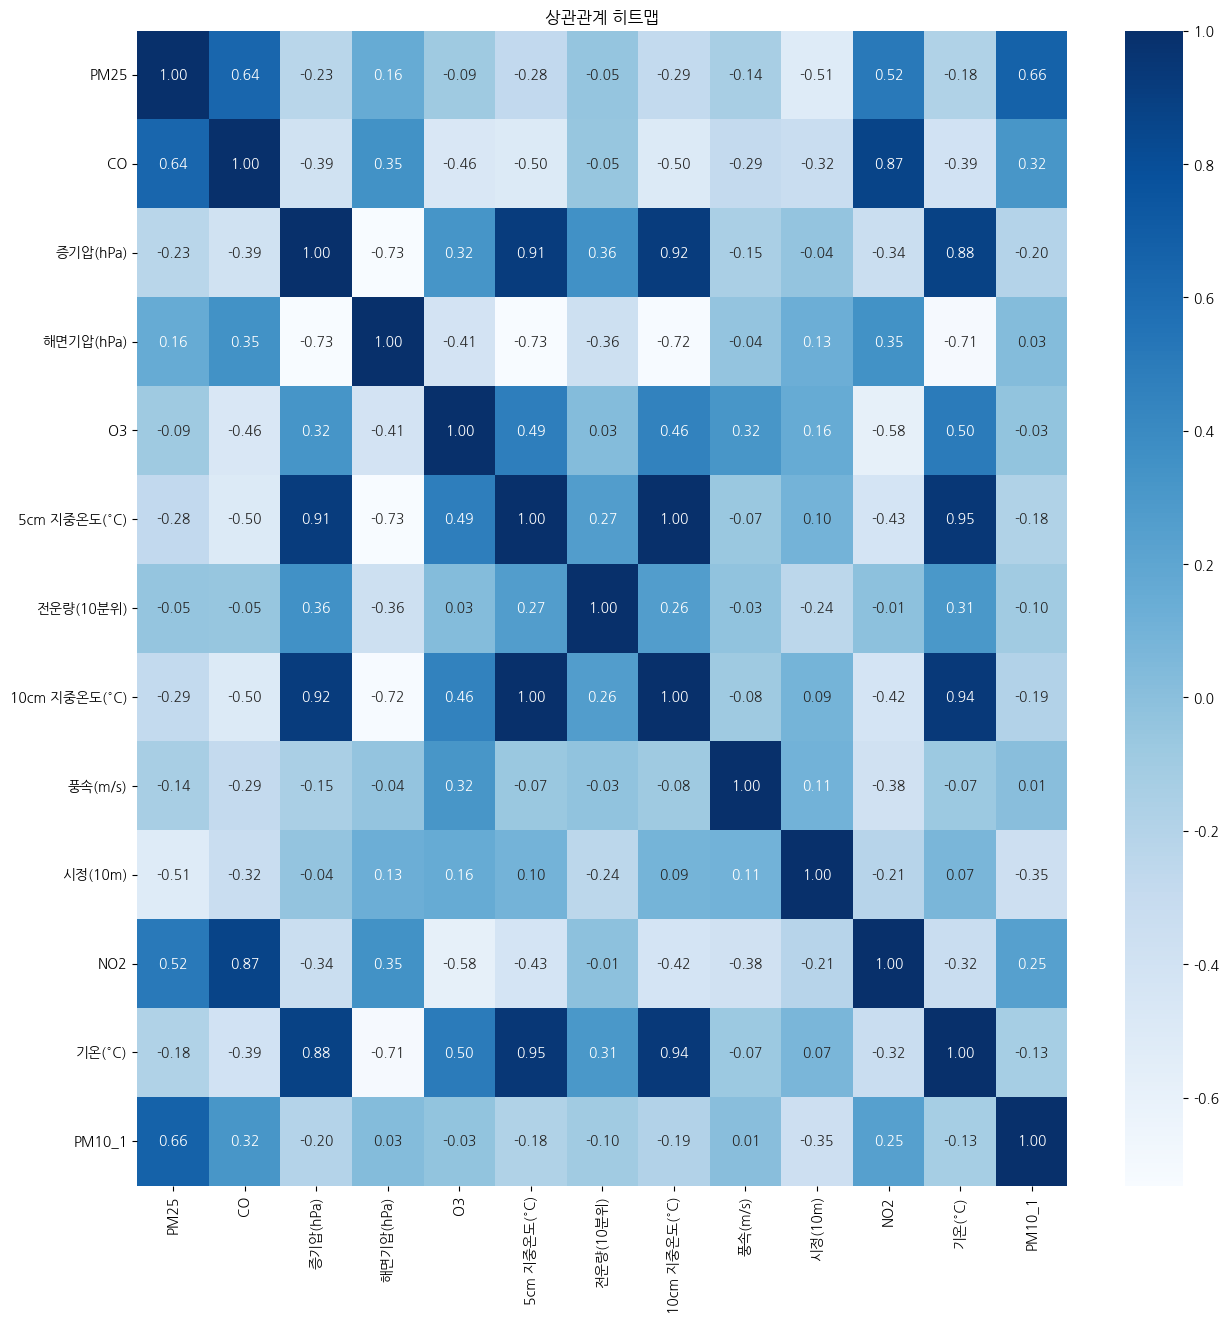

In [97]:
plt.figure(figsize=(15, 15))
sns.heatmap(df_21_corr, annot=True, cmap='Blues', fmt=".2f")
plt.title("상관관계 히트맵")
plt.show()

In [98]:
selected_features_final = vif_result['변수'].to_list()
selected_features_final

['PM25',
 'CO',
 '증기압(hPa)',
 '해면기압(hPa)',
 'O3',
 '5cm 지중온도(°C)',
 '전운량(10분위)',
 '10cm 지중온도(°C)',
 '풍속(m/s)',
 '시정(10m)',
 'NO2',
 '기온(°C)']

# [4] 모델 훈련 및 테스트

## 4-1. 전체 데이터로 돌려보기

#### X, y 설정

In [ ]:
df_21.columns

In [ ]:
X_train = df_21[[ 'SO2', 'CO', 'O3', 'NO2', '기온(°C)',
                  '강수량(mm)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
                  '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '3시간신적설(cm)',
                  '전운량(10분위)', '중하층운량(10분위)', '최저운고(100m )', '시정(10m)', '지면온도(°C)',
                  '5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)']].values
X_test = df_22[[ 'SO2', 'CO', 'O3', 'NO2', '기온(°C)',
                 '강수량(mm)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
                 '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '3시간신적설(cm)',
                 '전운량(10분위)', '중하층운량(10분위)', '최저운고(100m )', '시정(10m)', '지면온도(°C)',
                 '5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)']].values

y_train = df_21['PM10_1']
y_test = df_22['PM10_1']

In [ ]:
sc = StandardScaler()
X_train_sc = sc.fit_transform(X_train)
X_test_sc = sc.transform(X_test)

In [ ]:
y_train

### LinearRegression

In [ ]:
regressor = LinearRegression()
regressor.fit(X_train_sc, y_train)

In [ ]:
y_pred = regressor.predict(X_test_sc)

In [ ]:
y_pred

In [ ]:
y_test

In [ ]:
print(np.sqrt(mse(y_test, y_pred))) # RMSE

In [ ]:
r2_score(y_test, y_pred)

### 랜덤포레스트

In [ ]:
regressor = RFR(random_state=42)
regressor.fit(X_train, y_train)

In [ ]:
y_pred = regressor.predict(X_test)

In [ ]:
print(np.sqrt(mse(y_test, y_pred))) # RMSE

In [ ]:
r2_score(y_test, y_pred)

### XGBRegressor

In [ ]:
# XGBoost 모델 정의
xgb_model = XGBRegressor(random_state=42)

# 그리드 서치에서 탐색할 하이퍼파라미터 정의
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.1, 0.2],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

# 그리드 서치 수행
grid_search = GridSearchCV(estimator=xgb_model,
                           param_grid=param_grid,
                           scoring='neg_mean_squared_error',
                           cv=5,
                           verbose=1,
                           n_jobs=-1)

grid_search.fit(X_train, y_train)

In [ ]:
grid_search.best_params_

In [ ]:
xgb_model = grid_search.best_estimator_

In [ ]:
# 4. 예측
y_pred = xgb_model.predict(X_test)

# 5. 성능 평가
print(np.sqrt(mse(y_test, y_pred)))

In [ ]:
r2_score(y_test, y_pred)

## 4-2. 일부 변수만 선택해서 모델 훈련

#### X, y 설정

In [121]:
selected_features_final

['PM25',
 'CO',
 '증기압(hPa)',
 '해면기압(hPa)',
 'O3',
 '5cm 지중온도(°C)',
 '전운량(10분위)',
 '10cm 지중온도(°C)',
 '풍속(m/s)',
 '시정(10m)',
 'NO2',
 '기온(°C)']

In [99]:
X_train = df_21[selected_features_final].values
X_test = df_22[selected_features_final].values

In [100]:
X_train

array([[ 1.4e+01,  5.0e-01,  2.2e+00, ...,  2.0e+03,  1.6e-02, -8.7e+00],
       [ 1.4e+01,  6.0e-01,  2.1e+00, ...,  2.0e+03,  2.0e-02, -9.1e+00],
       [ 1.6e+01,  6.0e-01,  2.1e+00, ...,  2.0e+03,  2.5e-02, -9.3e+00],
       ...,
       [ 8.0e+00,  4.0e-01,  1.3e+00, ...,  2.0e+03,  2.0e-02, -6.3e+00],
       [ 9.0e+00,  4.0e-01,  1.3e+00, ...,  2.0e+03,  1.4e-02, -6.7e+00],
       [ 8.0e+00,  4.0e-01,  1.3e+00, ...,  2.0e+03,  1.1e-02, -7.5e+00]])

In [101]:
X_test

array([[ 9.00e+00,  4.00e-01,  1.30e+00, ...,  2.00e+03,  1.60e-02,
        -8.50e+00],
       [ 1.20e+01,  4.00e-01,  1.30e+00, ...,  2.00e+03,  1.60e-02,
        -9.20e+00],
       [ 9.00e+00,  4.00e-01,  1.30e+00, ...,  2.00e+03,  2.00e-02,
        -9.50e+00],
       ...,
       [ 8.00e+00,  4.00e-01,  6.50e+00, ...,  2.00e+03,  1.70e-02,
         1.16e+01],
       [ 7.00e+00,  4.00e-01,  6.40e+00, ...,  2.00e+03,  1.80e-02,
         1.05e+01],
       [ 5.00e+00,  3.00e-01,  6.80e+00, ...,  2.00e+03,  1.30e-02,
         9.30e+00]])

In [102]:
y_train = df_21['PM10_1']
y_test = df_22['PM10_1']
y_train

,PM10_1
0,25.0
1,27.0
2,23.0
3,24.0
4,26.0
...,...
8753,25.0
8754,26.0
8755,27.0
8756,20.0


In [103]:
sc = StandardScaler()
X_train_sc = sc.fit_transform(X_train)
X_test_sc = sc.transform(X_test)

### LinearRegression

In [104]:
regressor = LinearRegression()
regressor.fit(X_train_sc, y_train)

LinearRegression()

In [105]:
y_pred = regressor.predict(X_test_sc)

In [106]:
y_pred

array([ 8.34253531, 14.46062696,  7.2397034 , ..., 11.85637997,
       14.72353375,  5.06833073])

In [107]:
y_test

,PM10_1
0,23.0
1,20.0
2,20.0
3,19.0
4,24.0
...,...
2154,10.0
2155,11.0
2156,10.0
2157,11.0


In [108]:
print(np.sqrt(mse(y_test, y_pred))) # RMSE

22.46525077949697


In [109]:
r2_score(y_test, y_pred)

0.0863590776586578

### 랜덤포레스트

In [110]:
regressor = RFR(random_state=42)
regressor.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [111]:
y_pred = regressor.predict(X_test)

In [112]:
print(np.sqrt(mse(y_test, y_pred))) # RMSE

15.78566605653816


In [113]:
r2_score(y_test, y_pred)

0.5488937711496955

### XGBRegressor

In [114]:
# XGBoost 모델 정의
xgb_model = XGBRegressor(random_state=42)

# 그리드 서치에서 탐색할 하이퍼파라미터 정의
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.1, 0.2],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

# 그리드 서치 수행
grid_search = GridSearchCV(estimator=xgb_model,
                           param_grid=param_grid,
                           scoring='neg_mean_squared_error',
                           cv=5,
                           verbose=1,
                           n_jobs=-1)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 108 candidates, totalling 540 fits


GridSearchCV(cv=5,
             estimator=XGBRegressor(base_score=None, booster=None,
                                    callbacks=None, colsample_bylevel=None,
                                    colsample_bynode=None,
                                    colsample_bytree=None, device=None,
                                    early_stopping_rounds=None,
                                    enable_categorical=False, eval_metric=None,
                                    feature_types=None, gamma=None,
                                    grow_policy=None, importance_type=None,
                                    interaction_constraints=None,
                                    learning_rate=None, m...
                                    min_child_weight=None, missing=nan,
                                    monotone_constraints=None,
                                    multi_strategy=None, n_estimators=None,
                                    n_jobs=None, num_parallel_tree=None,
                                    random_state=42, ...),
             n_jobs=-1,
             param_grid={'colsample_bytree': [0.8, 1.0],
                         'learning_rate': [0.01, 0.1, 0.2],
                         'max_depth': [3, 4, 5], 'n_estimators': [50, 100, 200],
                         'subsample': [0.8, 1.0]},
             scoring='neg_mean_squared_error', verbose=1)

In [115]:
grid_search.best_params_

{'colsample_bytree': 0.8,
 'learning_rate': 0.01,
 'max_depth': 3,
 'n_estimators': 200,
 'subsample': 0.8}

In [116]:
xgb_model = grid_search.best_estimator_

In [117]:
# 4. 예측
y_pred = xgb_model.predict(X_test)

# 5. 성능 평가
print(np.sqrt(mse(y_test, y_pred)))

13.987748046053097


In [118]:
r2_score(y_test, y_pred)

0.6457999618973973

In [119]:
y_pred

array([22.357513, 27.660803, 22.357513, ..., 21.825094, 20.615767,
       19.451056], dtype=float32)

In [120]:
y_test.values

array([23., 20., 20., ..., 10., 11., 11.])